Eenvoudiger gemaakt, voor max. 2 hidden layers. Om te zien of berekening zo sneller gaat. Conclusies: geen betekenisvol verschil.

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time

In [72]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [73]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [74]:
def grad(act, wt, bs, ins, outs):
    
    gr_act = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    ind = []   
    for i in range(L):
        ind.append(list(range(len(act[i]))))


    for i in range(L-1): 
        for j in range(len(act[i])):
            gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * (wt[-1][k][j] if i == L-2 
                else sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * wt[-2][l][j] 
                          for l in ind[-2]])) for k in ind[-1]])
    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                gr_bs[i][j] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])
        elif i == 0:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j])
        else:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])

    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]
        elif i == 0:
            for j in range(len(bs[i])):
                for k in range(len(ins)):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j]) * ins[k]
        else:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]         

    
    return gr_act, gr_wt, gr_bs

In [75]:
def neural_network(inputs, outputs, nodes_hidden_layers, max_bias, max_weight, learning_rate, iterations, fraction):

    biases = []
    for i in range(len(nodes_hidden_layers)):
        biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

    biases.append(np.random.uniform(-max_bias, max_bias, len(outputs[0])))
    
    weights = []
    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], len(inputs[0]))))
    
    for i in range(len(nodes_hidden_layers) - 1):
        weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

    weights.append(np.random.uniform(-max_weight, max_weight, (len(outputs[0]), nodes_hidden_layers[-1])))

    cost = []

    number = round(fraction*len(inputs))
    
    for k in range(iterations):

        if number == len(outputs):
            inputs_part = inputs
            outputs_part = outputs

        else:
            end = int((number*(k+1)/len(outputs) - number*(k+1)//len(outputs))*len(outputs)) - 1
            start = end - (number-1)

            if start < 0:
                start = start + len(outputs)
            if end < 0:
                end = end + len(outputs)
    
            if start > end:
                inputs_part = np.vstack((inputs[start:], inputs[:end+1]))
                outputs_part = np.vstack((outputs[start:], outputs[:end+1]))
            else:
                inputs_part = inputs[start:end+1]
                outputs_part = outputs[start:end+1]

        iter_cost = 0

        gr_b = [0*bias for bias in biases]
        gr_w = [0*weight for weight in weights]
        gr_act = gr_b
        
        for j in range(inputs_part.shape[0]):        
            
            activations = det_activations(inputs_part[j], weights, biases)
            iter_cost +=  (1/inputs_part.shape[0]) * sum([(activations[-1].tolist()[i] - outputs_part[j][i])**2 
                                                          for i in range(len(outputs_part[j]))])
        
            gr_act_p, gr_w_p, gr_b_p = grad(activations, weights, biases, inputs_part[j], outputs_part[j])

            gr_b = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_b, gr_b_p)]
            gr_w = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_w, gr_w_p)]
            gr_act = [g + (1/inputs_part.shape[0])*gp for g, gp in zip(gr_act, gr_act_p)]
            
        weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
        biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

        cost.append(iter_cost)

    return activations, weights, biases, cost

In [76]:
inputs = np.random.rand(4,20)
outputs = [[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]]

Time taken for 1 layer of 5 nodes: 0.8501548767089844 seconds
Time taken for 2 layes of 5 nodes: 1.905184030532837 seconds


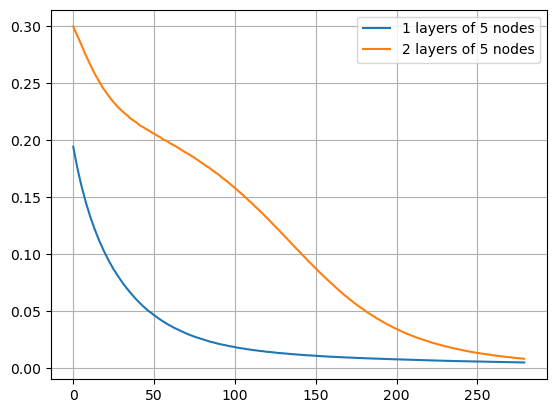

In [77]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 300, 1) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.grid();
plt.legend();

In [82]:
outs = outputs[0]
act = activations
bs = biases
wt = weights

delta = [0*a for a in act]
gr_bs = [0*b for b in bs]
gr_wt = [0*w for w in wt]

L = len(act)

#for j in range(len(outs)):
    #delta[-1][j] = 2*(act[-1][j] - outs[j]) * sigma_der(np.dot(wt[-1][j], act[-2]) + bs[-1][j])

delta[-1] = 2*(act[-1] - outs) * sigma_der(np.dot(wt[-1], act[-2]) + bs[-1])

delta

[array([0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0.]),
 array([-0.32481577, -0.01401201,  0.01956741, -0.03699729, -0.26377066,
        -0.09259911])]

In [85]:
wt[1]

array([[ 0.46327249, -0.41458227,  0.16457286, -0.64742829, -0.38414064],
       [ 0.38204793, -0.39332265, -0.5768448 , -0.25738931, -0.03689414],
       [ 0.07916391,  0.82706619, -0.78990664, -0.36204589, -0.50134274],
       [ 0.46780334, -0.82526928, -0.28574372, -0.7959513 ,  0.09410226],
       [-0.99242482,  0.38485188, -0.52957108, -0.90576939,  0.16032007]])

In [91]:
np.round(wt[1].T,2)

array([[ 0.46,  0.38,  0.08,  0.47, -0.99],
       [-0.41, -0.39,  0.83, -0.83,  0.38],
       [ 0.16, -0.58, -0.79, -0.29, -0.53],
       [-0.65, -0.26, -0.36, -0.8 , -0.91],
       [-0.38, -0.04, -0.5 ,  0.09,  0.16]])

In [89]:
act[1]

array([0.163, 0.829, 0.2  , 0.57 , 0.592])

In [92]:
np.dot(np.round(wt[1].T,2), act[1])

array([ 0.08782, -0.47228, -1.0918 , -1.38821, -0.04908])

In [93]:
0.46*0.163 + 0.38*0.829 + 0.08*0.2 + 0.47*0.57 - 0.99*0.592

0.08782000000000001

Time taken for 1 layer of 5 nodes: 0.4865999221801758 seconds
Time taken for 2 layes of 5 nodes: 1.0160069465637207 seconds


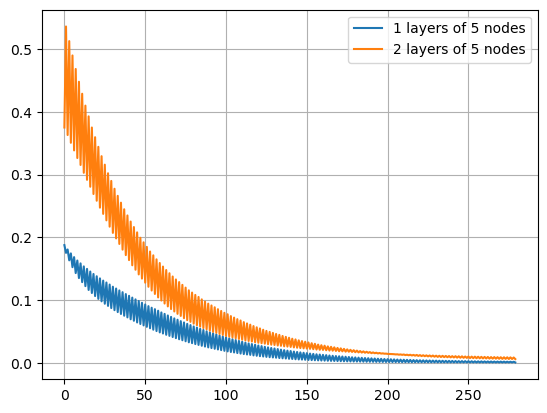

In [11]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 300, 0.5) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 8 nodes: 1.1638240814208984 seconds
Time taken for 2 layes of 8 nodes: 3.0174758434295654 seconds


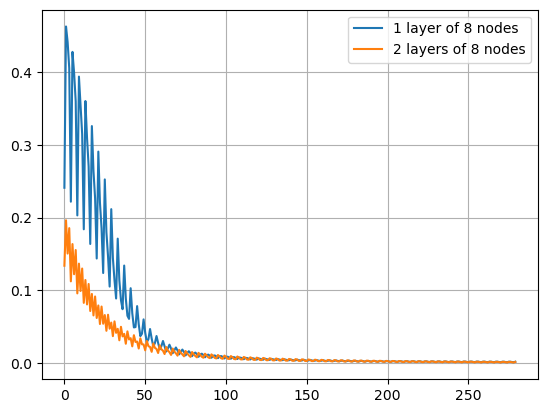

In [12]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 1 layer of 8 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [8, 8], 1, 1, 1, 300, 0.75) 
end = time.time()
print("Time taken for 2 layes of 8 nodes:", end - start, "seconds")

#laatste 5: max_bias, max_weight, learning_rate, iterations, fraction

plt.plot(cost_a[20:], label="1 layer of 8 nodes");
plt.plot(cost_b[20:], label="2 layers of 8 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 5 nodes: 5.741215944290161 seconds
Time taken for 2 layes of 5 nodes: 12.105011224746704 seconds


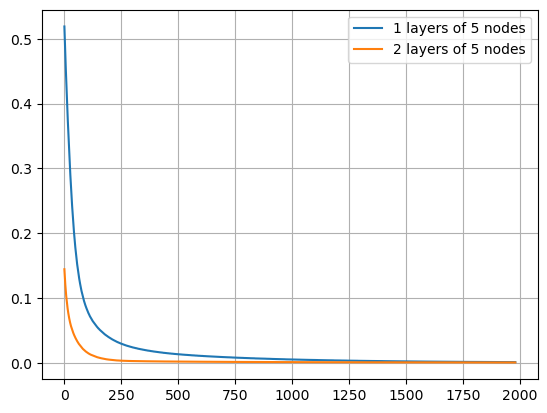

In [13]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 1, 1, 2000, 1) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.grid();
plt.legend();

In [14]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_train.csv")

In [15]:
X_train = train_data.drop('label', axis=1).to_numpy()/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()

X_test = test_data.drop('label', axis=1).to_numpy()/255
y_test = test_data['label']

In [16]:
train_data['label'].head()

0    5
1    0
2    4
3    1
4    9
Name: label, dtype: int64

Time taken for 2 layers of 16 nodes: 889.2115619182587 seconds


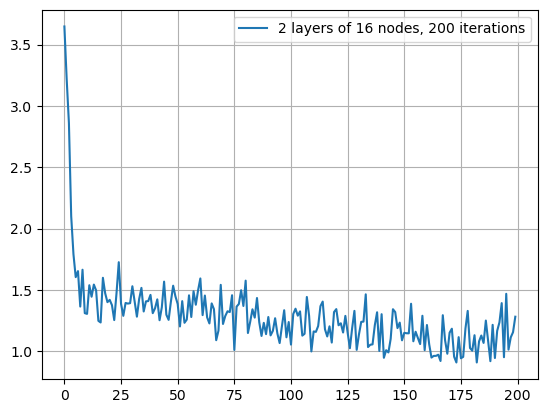

In [17]:
start = time.time()  
activations, weights_2, biases_2, cost_2 = neural_network(X_train, y_train, [16, 16], 1, 1, 1, 200, 0.001) 
end = time.time()

print("Time taken for 2 layers of 16 nodes:", end - start, "seconds")

plt.plot(cost_2, label="2 layers of 16 nodes, 200 iterations");
plt.grid();
plt.legend();

In [18]:
y_test

0       7
1       2
2       1
3       0
4       4
       ..
9995    2
9996    3
9997    4
9998    5
9999    6
Name: label, Length: 10000, dtype: int64

In [19]:
def predict(inputs, weights, biases, labels):

    outputs = []

    for i in range(len(inputs)):

        activations = det_activations(inputs[i], weights, biases)
        outputs.append(labels[np.argmax(activations[-1])])

    return outputs

In [20]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [21]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

In [22]:
y_predict_2 = predict(X_test, weights_2, biases_2, labels)
accuracy_score(y_test,y_predict_2)

0.4021

In [23]:
y_test[:10]

0    7
1    2
2    1
3    0
4    4
5    1
6    4
7    9
8    5
9    9
Name: label, dtype: int64

In [24]:
y_predict_2[:10]

[2, 0, 1, 0, 5, 1, 2, 9, 4, 3]

Time taken: 744.8177590370178 seconds


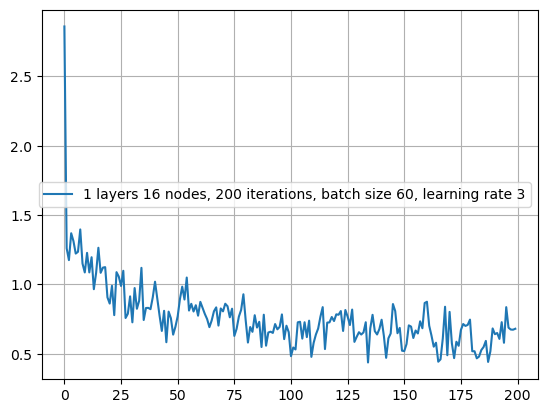

In [27]:
start = time.time()  
activations, weights_2, biases_2, cost_2 = neural_network(X_train, y_train, [16], 1, 1, 3, 200, 0.001) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_2, label="1 layers 16 nodes, 200 iterations, batch size 60, learning rate 3");
plt.grid();
plt.legend();

In [28]:
y_predict_2 = predict(X_test, weights_2, biases_2, labels)
accuracy_score(y_test,y_predict_2)

0.6749

Time taken: 3790.128632068634 seconds
Accuracy: 0.7806


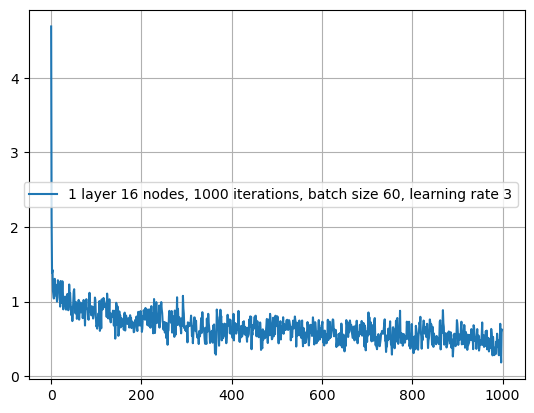

In [33]:
start = time.time()  
activations, weights_2, biases_2, cost_2 = neural_network(X_train, y_train, [16], 1, 1, 3, 1000, 0.001) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_2, label="1 layer 16 nodes, 1000 iterations, batch size 60, learning rate 3");
plt.grid();
plt.legend();

y_predict_2 = predict(X_test, weights_2, biases_2, labels)
print('Accuracy: ' + str(accuracy_score(y_test,y_predict_2)))

In [34]:
y_predict_2[:10]

[7, 2, 1, 0, 4, 1, 4, 9, 4, 9]

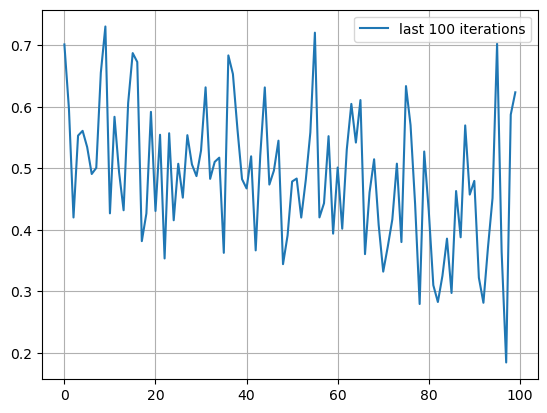

In [37]:
plt.plot(cost_2[-100:], label='last 100 iterations');
plt.grid();
plt.legend();